# 20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.472729,0.077122,15
1,DAGMA_Linear,0.107246,0.078030,15
2,DAGMA_Nonlinear,0.275731,0.066922,15
3,DAS,0.209763,0.083171,15
4,DirectLiNGAM,0.198694,0.084622,15
5,FCI,0.131343,0.064557,15
6,GES,0.531893,0.091296,15
7,GOLEM,0.103299,0.067002,15
8,GRaSP,0.470654,0.085475,15
9,GraNDAG,0.045754,0.033599,15


,model,mean,std,size
0,AVICI,44.933333,8.438574,15
1,DAGMA_Linear,58.933333,8.163216,15
2,DAGMA_Nonlinear,51.848889,6.640686,15
3,DAS,71.533333,13.303419,15
4,DirectLiNGAM,77.933333,20.926629,15
5,FCI,53.857778,9.206756,15
6,GES,41.666667,10.997835,15
7,GOLEM,63.133333,10.098562,15
8,GRaSP,42.182222,7.921058,15
9,GraNDAG,56.400000,6.173677,15


,model,mean,std,size
0,AVICI,0.723965,0.137357,15
1,DAGMA_Linear,0.199129,0.126130,15
2,DAGMA_Nonlinear,0.501539,0.106505,15
3,DAS,0.217578,0.087810,15
4,DirectLiNGAM,0.192859,0.087095,15
5,FCI,0.811397,0.273622,15
6,GES,0.671341,0.168710,15
7,GOLEM,0.171592,0.106492,15
8,GRaSP,0.762938,0.130779,15
9,GraNDAG,0.332835,0.253470,15


,model,mean,std,size
0,AVICI,0.361802,0.085278,15
1,DAGMA_Linear,0.074675,0.057119,15
2,DAGMA_Nonlinear,0.194854,0.058376,15
3,DAS,0.205476,0.083107,15
4,DirectLiNGAM,0.208779,0.084146,15
5,FCI,0.072774,0.039218,15
6,GES,0.448462,0.071099,15
7,GOLEM,0.075610,0.051307,15
8,GRaSP,0.345004,0.073980,15
9,GraNDAG,0.025152,0.019069,15


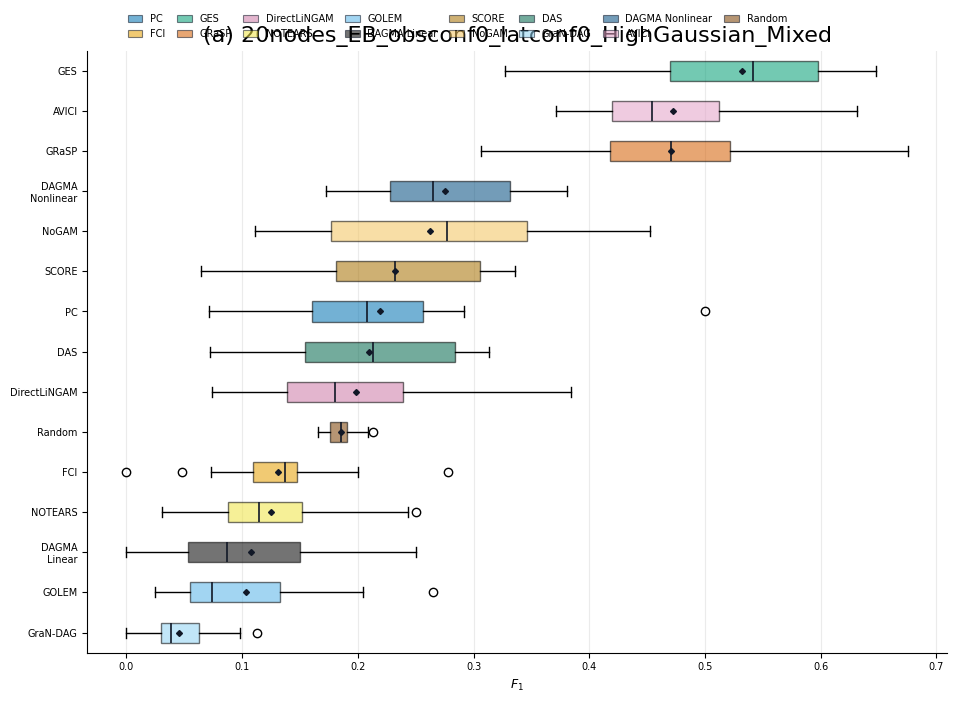

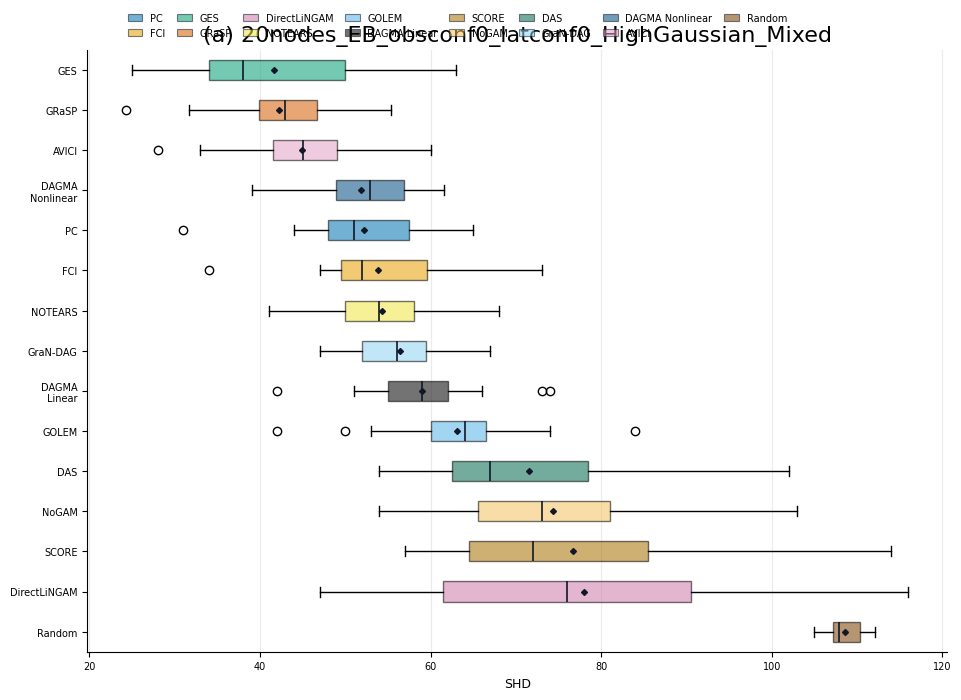

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.198830
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.000000
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.049398
9,13,GraNDAG,0.000000


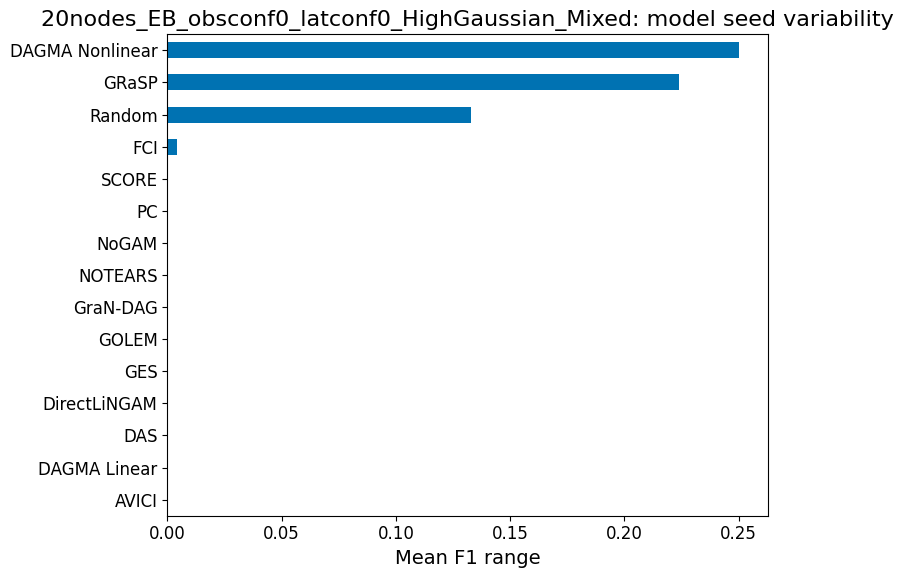

,model_seed,model,f1_range
0,0,AVICI,0.260150
1,0,DAGMA_Linear,0.250000
2,0,DAGMA_Nonlinear,0.397833
3,0,DAS,0.241101
4,0,DirectLiNGAM,0.310996
5,0,FCI,0.277778
6,0,GES,0.320301
7,0,GOLEM,0.240316
8,0,GRaSP,0.446702
9,0,GraNDAG,0.112676


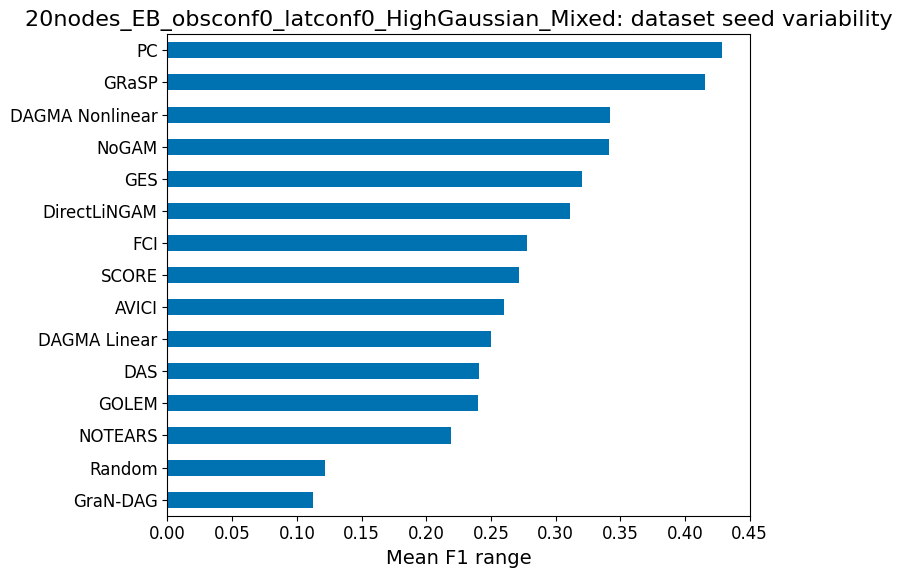

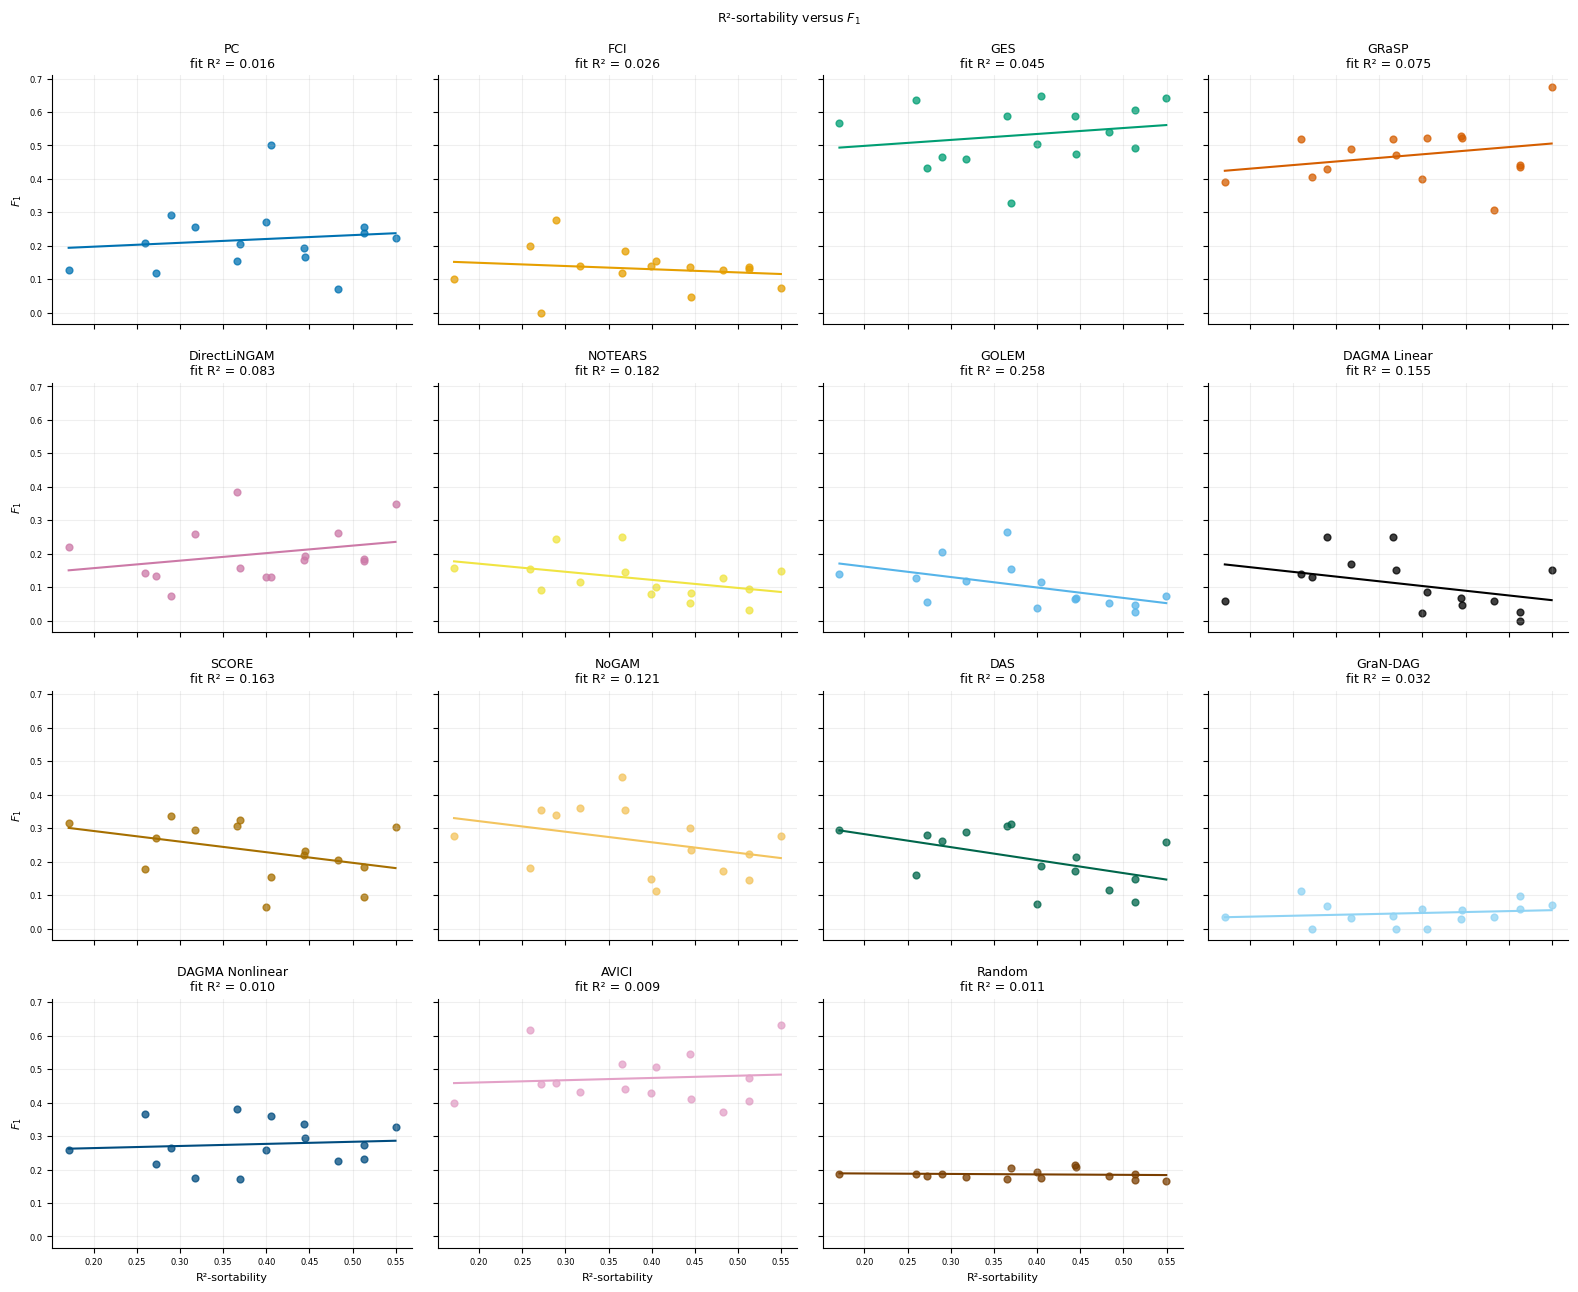

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,AVICI,0.631579,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DAGMA_Linear,0.150000,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DAGMA_Nonlinear,0.327771,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DAS,0.258621,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DirectLiNGAM,0.349515,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,FCI,0.072727,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GES,0.642857,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GOLEM,0.074074,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GRaSP,0.675779,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GraNDAG,0.071429,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.629344,0.289575,259,163,0,75,0,20,2000
1,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
2,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.848276,0.365517,145,123,0,53,0,20,2000
3,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.735751,0.170984,193,142,0,33,0,20,2000
4,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.845283,0.513208,265,224,0,136,0,20,2000
5,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.731707,0.404878,205,150,0,83,0,20,2000
6,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.781250,0.259375,320,250,0,83,0,20,2000
7,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.687151,0.399441,358,246,0,143,0,20,2000
8,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.689320,0.483010,412,284,0,199,0,20,2000
9,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.755344,0.444181,421,318,0,187,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.094846,0.008996,0.067174,0.446768,0.736700,0.023235,0.934494
1,DAGMA_Linear,15,-0.393245,0.154642,-0.281793,0.216153,0.147032,-0.418980,0.120073
2,DAGMA_Nonlinear,15,0.102139,0.010432,0.062773,0.251471,0.717192,0.096515,0.732222
3,DAS,15,-0.507857,0.257919,-0.387899,0.359678,0.053272,-0.514746,0.049600
4,DirectLiNGAM,15,0.288732,0.083366,0.224380,0.111976,0.296633,0.296694,0.282905
5,FCI,15,-0.161328,0.026027,-0.095644,0.168307,0.565698,-0.235925,0.397269
6,GES,15,0.212085,0.044980,0.177815,0.463171,0.447950,0.300268,0.276866
7,GOLEM,15,-0.507646,0.257704,-0.312359,0.224019,0.053388,-0.600536,0.017920
8,GRaSP,15,0.273780,0.074956,0.214907,0.387597,0.323449,0.309205,0.262112
9,GraNDAG,15,0.179762,0.032314,0.055467,0.024318,0.521476,0.213454,0.444956


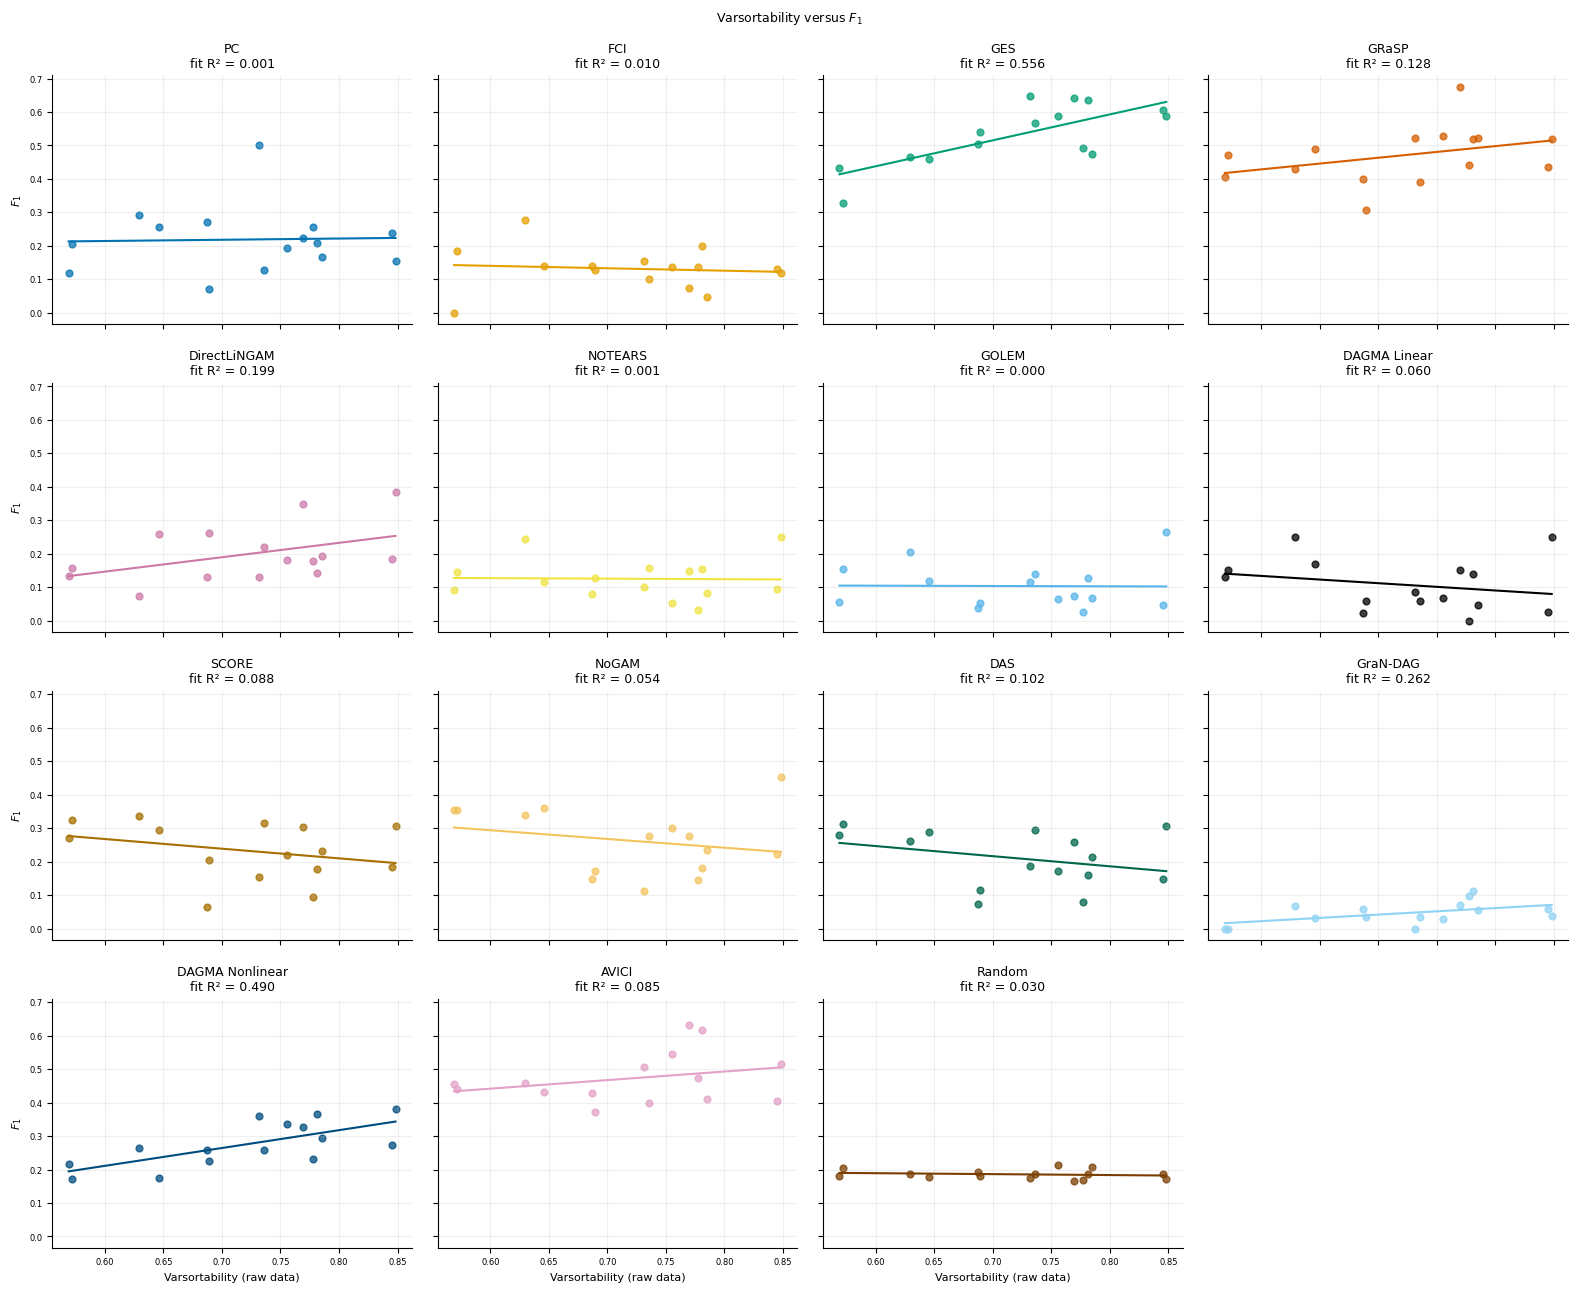

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,AVICI,0.631579,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DAGMA_Linear,0.150000,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DAGMA_Nonlinear,0.327771,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DAS,0.258621,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DirectLiNGAM,0.349515,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,FCI,0.072727,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GES,0.642857,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GOLEM,0.074074,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GRaSP,0.675779,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GraNDAG,0.071429,15,20,EB,0,0,HighGaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.629344,0.289575,259,163,0,75,0,20,2000
1,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.769634,0.549738,191,147,0,105,0,20,2000
2,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.848276,0.365517,145,123,0,53,0,20,2000
3,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.735751,0.170984,193,142,0,33,0,20,2000
4,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.845283,0.513208,265,224,0,136,0,20,2000
5,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.731707,0.404878,205,150,0,83,0,20,2000
6,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.781250,0.259375,320,250,0,83,0,20,2000
7,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.687151,0.399441,358,246,0,143,0,20,2000
8,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.689320,0.483010,412,284,0,199,0,20,2000
9,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.755344,0.444181,421,318,0,187,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.291409,0.084919,0.255912,0.288091,0.291974,0.200000,0.474814
1,DAGMA_Linear,15,-0.244962,0.060006,-0.217655,0.264282,0.378889,-0.250448,0.367961
2,DAGMA_Nonlinear,15,0.699899,0.489859,0.533354,-0.109078,0.003673,0.703571,0.003424
3,DAS,15,-0.319231,0.101909,-0.302333,0.427893,0.246138,-0.246429,0.375951
4,DirectLiNGAM,15,0.446392,0.199266,0.430139,-0.111646,0.095324,0.471429,0.076070
5,FCI,15,-0.098563,0.009715,-0.072455,0.183618,0.726737,-0.264286,0.341174
6,GES,15,0.745446,0.555690,0.774957,-0.027231,0.001423,0.614286,0.014834
7,GOLEM,15,-0.012563,0.000158,-0.009585,0.110215,0.964556,-0.067857,0.810109
8,GRaSP,15,0.357537,0.127833,0.347994,0.219580,0.190750,0.417857,0.121173
9,GraNDAG,15,0.511523,0.261656,0.195704,-0.095445,0.051294,0.534054,0.040301


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,AVICI,r2_sortability,15,0.023235,0.934494,estimated,1.000000
1,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DAGMA_Linear,r2_sortability,15,-0.418980,0.120073,estimated,1.000000
2,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DAGMA_Nonlinear,r2_sortability,15,0.096515,0.732222,estimated,1.000000
3,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DAS,r2_sortability,15,-0.514746,0.049600,estimated,0.694402
4,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,DirectLiNGAM,r2_sortability,15,0.296694,0.282905,estimated,1.000000
5,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,FCI,r2_sortability,15,-0.235925,0.397269,estimated,1.000000
6,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GES,r2_sortability,15,0.300268,0.276866,estimated,1.000000
7,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GOLEM,r2_sortability,15,-0.600536,0.017920,estimated,0.268806
8,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GRaSP,r2_sortability,15,0.309205,0.262112,estimated,1.000000
9,benchmark,untuned,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,GraNDAG,r2_sortability,15,0.213454,0.444956,estimated,1.000000
